# V47 — ¿Se justifica la red? Un solo procedimiento, dos arranques

**El procedimiento (siempre igual, 3 pasos).**
1. **Arranque:** un primer intento de diseño.
2. **MCO no lineal** (números reales): ajusta la curva del sujeto con el modelo de pared gruesa. Si la curva viene medida (con ruido o en pocas presiones), la suaviza: la curva de un injerto no puede tener saltos.
3. **Láminas enteras** de 0,025 mm con **minimax no lineal** contra la curva del paso 2: se elige la combinación de láminas cuyo peor punto es el más chico.

**Los dos caminos** difieren solo en el paso 1:
- **A) Sin red:** el arranque es el MCO lineal de pared delgada.
- **B) Con red:** el arranque lo da la red neuronal.

El diseño entero se compara siempre con la **curva original** (verdadera) del sujeto.

**Qué se mide.** Celda 8: curvas limpias. Celda 10: curvas medidas (ruido 0,3 %, 10 presiones, 10 presiones con ruido 0,2 %). La red se justifica si evita diseños que fallan.

**Celdas.** 0 configuración · 1 sujetos y curva λθ(P) · 2 arterias sintéticas · 3 injerto y materiales · 4 ajuste por mínimos cuadrados · 5 dataset con etiquetas · 6 partición · 7 red (carga) · **8 los dos caminos con curvas limpias** · **9 figuras** · **10 curvas medidas**. La presión va siempre en la ordenada: kPa a la izquierda, mmHg a la derecha; abajo, escala relativa P/13,332 kPa.

## Celda 0 — Configuración (ejecutar siempre primero)

In [1]:
# CELDA 0: CONFIGURACIÓN (ejecutar siempre primero)
#   V47 = un solo procedimiento en 3 pasos (arranque → MCO no lineal, que ajusta y suaviza → láminas enteras con minimax contra la
#   curva del ajuste) y DOS caminos que solo difieren en el arranque: A) sin red (MCO lineal de pared delgada), B) con red.
#   V46 = V45 con TRES caminos al diseño ENTERO, comparados contra la curva original de pared gruesa:
#     1) minimax no lineal directo → láminas · 2) mínimos cuadrados no lineales → láminas · 3) red → minimax no lineal → láminas.
#   V45 = V44 con láminas de 0,025 mm (adoptado). V44 = V43 + diseño por el criterio del PEOR PUNTO (minimax no lineal) y paso a LÁMINAS ENTERAS de espesor fijo.
#   (La red y las etiquetas son las de V43: la red sigue siendo el punto de partida.)
#   V43: PARED GRUESA con geometría documentada y presiones fisiológicas. Cada arteria (y cada injerto) se describe por su curva
#   diámetro–presión: λθ(P), el estiramiento circunferencial en r_m para P de 60 a 200 mmHg (la misma ventana para todos).
#   El injerto es un tubo de capas (una por material); cada material es una RECTA TRUNCADA σ = E·max(0, λ − κ).
#   El aporte de cada capa depende de dónde está en la pared → el problema espesores → curva es NO lineal.
import os
import numpy as np

N_BASES = 6                      # ← número de materiales: 5 o 6
VERSION = f"v47_{N_BASES}"
SEED = 42
DIR_MASSON = "."
ENTRENAR = "auto"                # "auto": carga la red si sus archivos están; si no, la entrena

# Ventana de presión (igual para todos los sujetos) y conversión
MMHG = 0.133322                  # kPa por mmHg
P_MIN_MMHG, P_MAX_MMHG, N_P = 60.0, 200.0, 141
P_GRID = np.linspace(P_MIN_MMHG, P_MAX_MMHG, N_P) * MMHG          # [kPa]
P_REF_KPA = 13.332               # escala adimensional de la presión: P/P_ref, con P_ref = 13,332 kPa (= 100 mmHg)
P_REF_MMHG = P_REF_KPA / MMHG
X_FINO = np.linspace(0.98, 1.40, 841)                               # λθ donde se calcula P(λ) antes de invertir

# Geometría documentada
#   R_m, Θ0, λz: Masson et al. (2011), Tablas 2 y 4 (por sujeto).
#   Espesor de la pared (íntima–media) h: mediana de referencia del IMT de carótida común por edad y sexo,
#   Engelen et al. (2013), Eur Heart J 34:2368–2380, Tabla 3 (ecotracking, el mismo tipo de equipo que Masson).
IMT_ENGELEN = {"M": (15, 401.0, 26.2), "F": (15, 396.0, 24.9)}       # (edad 15 años, mediana a esa edad [µm], aumento cada 5 años [µm])
N_RADIAL = 60

# Materiales: nudos y módulos de las bases de V41 (rectas truncadas). E_j = PEND_MAX_j [kPa por unidad de λ]
MATERIALES = {6: dict(nudos=[0.8193, 1.0227, 1.0774, 1.1099, 1.1318, 1.1478], E=[246.3, 827.8, 694.6, 1155.7, 1664.6, 2222.6]),
              5: dict(nudos=[0.8228, 1.0243, 1.0881, 1.1226, 1.1447], E=[251.1, 871.4, 1038.3, 1774.8, 2581.5])}
H_CAPA_MAX = 3.0                 # cota física de búsqueda de una capa [mm] (no es una restricción de diseño)
N_GAUSS_CAPA = 8

ERROR_MAX_PCT = 3.0
ESP_LAMINA_MM = 0.025               # ← espesor de una lámina [mm]: cada capa = n láminas enteras (n ≥ 0)
FRAC_SUJETOS_TEST = 0.25
ETQ_P, ETQ_L = "P [kPa]", r"$\lambda_\theta$ (en $r_m$)"

_v = VERSION
ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL = (f"modelo_rn_{_v}.keras", f"scalers_{_v}.pkl", f"historial_entrenamiento_{_v}.csv")
ARCHIVO_ETIQUETAS = f"etiquetas_pared_gruesa_{_v}.npz"
if ENTRENAR == "auto":
    ENTRENAR = not all(os.path.exists(f) for f in (ARCHIVO_MODELO, ARCHIVO_SCALERS, ARCHIVO_HISTORIAL))
print(f"✅ {VERSION} | {N_BASES} materiales | pared gruesa | curva λθ(P) para P de {P_MIN_MMHG:g} a {P_MAX_MMHG:g} mmHg | "
      f"red: {'se entrena' if ENTRENAR else 'se carga de ' + ARCHIVO_MODELO}")

✅ v47_6 | 6 materiales | pared gruesa | curva λθ(P) para P de 60 a 200 mmHg | red: se carga de modelo_rn_v47_6.keras


## Celda 1 — Los 41 sujetos: geometría documentada y curva diámetro–presión λθ(P)

✅ 41 sujetos | espesor (IMT, Engelen 2013): 0.426–0.684 mm (mediana 0.610) | λθ en 60 mmHg: 1.019–1.166 | en 200 mmHg: 1.122–1.225
   test: NT02, NT08, NT10, NT11, HT03, HT05, HT13, HT14, HT19, HT24
  id  age gender  Rm_mm  h_mm  lambda_60  lambda_200
NT01   62      F  4.261 0.630      1.090       1.157
NT02   60      M  4.691 0.637      1.096       1.176
NT03   31      M  4.305 0.485      1.115       1.202
NT04   31      M  4.672 0.485      1.142       1.225
NT05   34      F  4.203 0.491      1.080       1.179
NT06   53      F  3.957 0.585      1.081       1.161
NT07   21      F  3.827 0.426      1.081       1.184
NT08   25      M  4.856 0.453      1.166       1.214
NT09   42      F  4.506 0.530      1.088       1.166
NT10   55      M  4.770 0.611      1.054       1.133
NT11   64      M  5.566 0.658      1.060       1.134
NT12   60      F  4.876 0.620      1.097       1.169
NT13   61      F  4.924 0.625      1.087       1.167
NT14   39      F  3.539 0.516      1.085       1.167
NT15  

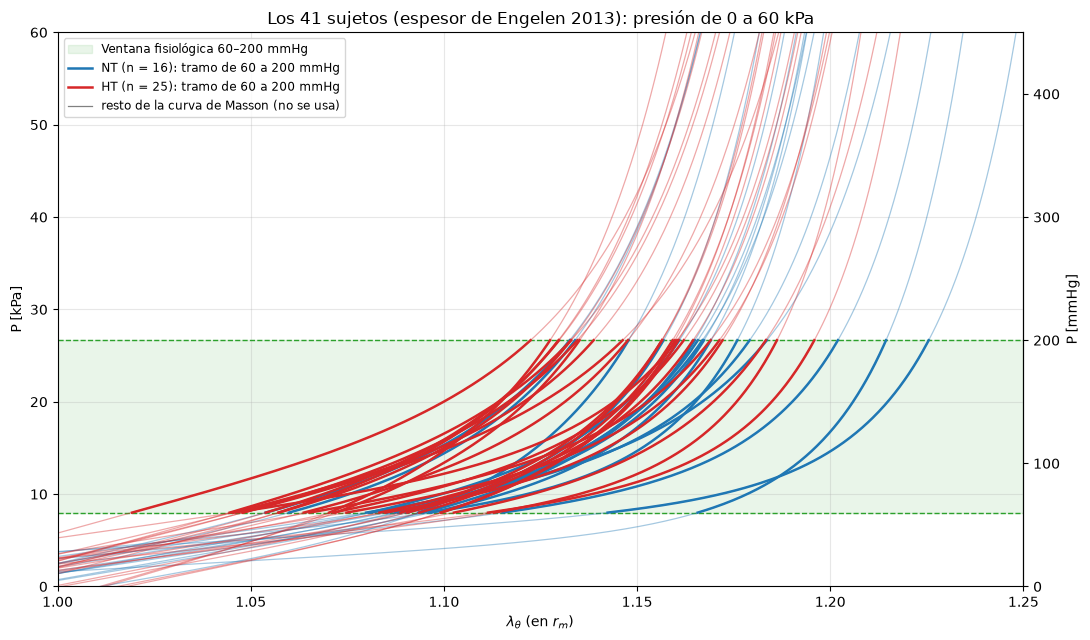

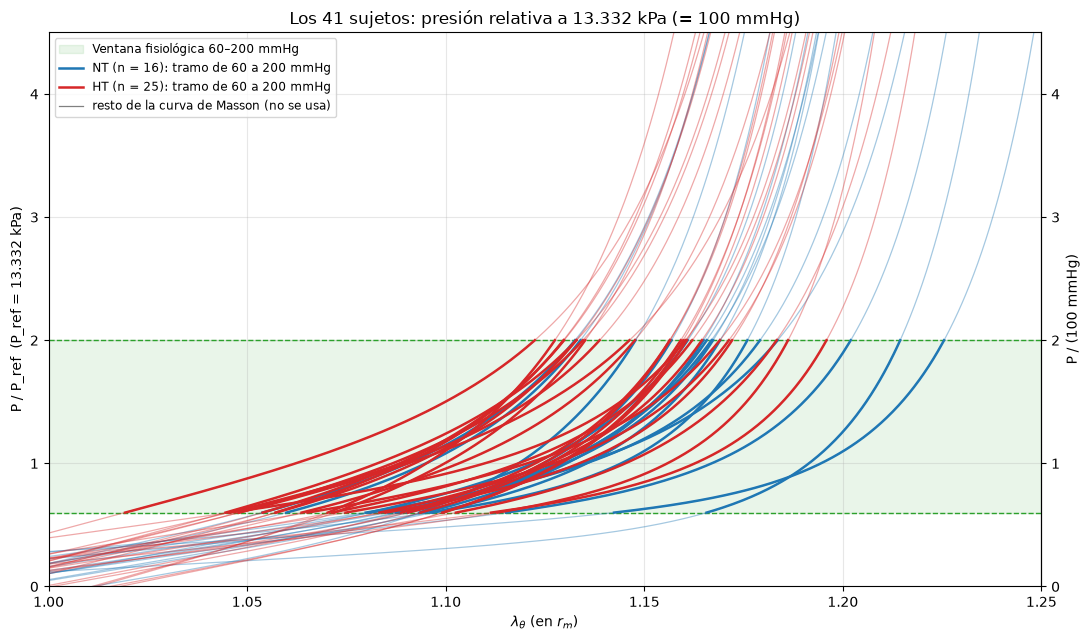

In [2]:
# CELDA 1: LOS 41 SUJETOS — ley de Masson, geometría documentada y curva diámetro–presión λθ(P)
#   P(λ) = ∫ σθθ/r dr sobre la pared (Masson: incompresible, ángulo de apertura Θ0, λz fijo). El espesor h de cada sujeto es el
#   IMT de referencia para su edad y sexo (Engelen 2013). Luego se invierte: λθ(P) en la ventana de P_MIN a P_MAX mmHg.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

COLS_PARAM = ["Rm_mm", "Theta0_deg", "lambda_ax", "c_kPa", "c1_kPa", "c2", "c1circ_kPa", "c2circ", "alpha_deg",
              "Tm_kPa", "lambda0", "lambda_m", "a_kPa", "b"]


def imt_mm(edad, sexo):
    """Mediana del IMT de carótida común [mm] para la edad y el sexo (Engelen et al. 2013, Tabla 3; lineal entre 15 y 85 años)."""
    e0, v0, d5 = IMT_ENGELEN[sexo]
    return (v0 + d5 * (np.clip(edad, 15, 85) - e0) / 5.0) / 1000.0


def sigma_masson(lt, p):
    """σθθ(λθ) [kPa]: elastina neo-Hookeana + 4 familias de colágeno + tono activo (Masson et al. 2011)."""
    lt = np.asarray(lt, float)
    lz, al = p["lambda_ax"], np.deg2rad(p["alpha_deg"])
    lam_d = np.sqrt(lt ** 2 * np.sin(al) ** 2 + lz ** 2 * np.cos(al) ** 2)
    suma = np.zeros_like(lt)
    for lam_k, c1, c2, ang in [(lz * np.ones_like(lt), p["c1_kPa"], p["c2"], 0.0), (lt, p["c1circ_kPa"], p["c2circ"], np.pi / 2),
                               (lam_d, p["c1_kPa"], p["c2"], al), (lam_d, p["c1_kPa"], p["c2"], -al)]:
        E = lam_k ** 2 - 1.0
        suma = suma + c1 * E * np.exp(c2 * E ** 2) * np.sin(ang) ** 2
    activo = p["Tm_kPa"] * lt * (1.0 - ((p["lambda_m"] - lt) / (p["lambda_m"] - p["lambda0"])) ** 2)
    return -p["c_kPa"] * (1.0 / (lt * lz)) ** 2 + p["c_kPa"] * lt ** 2 + lt ** 2 * suma + activo


def presion_arteria(lt_m, p):
    """P(λθ en r_m) [kPa], pared gruesa con la cinemática de Masson y espesor p['h_mm']."""
    lt_m = np.asarray(lt_m, float)
    Th, lz, Rm, H = np.deg2rad(p["Theta0_deg"]), p["lambda_ax"], p["Rm_mm"], p["h_mm"]
    rm = lt_m * Th * Rm / np.pi
    rr = (rm - H)[:, None] + H * np.linspace(0.0, 1.0, N_RADIAL)[None, :]
    R = np.sqrt(np.maximum(Rm ** 2 - (np.pi * lz / Th) * (rm[:, None] ** 2 - rr ** 2), 1e-12))
    return np.trapezoid(sigma_masson(np.pi * rr / (Th * R), p) / rr, rr, axis=1)


def invertir(P_de_l, x=X_FINO):
    """λ(P) en P_GRID a partir de P(λ) en x; None si P(λ) no es creciente o no cubre la ventana."""
    P = np.maximum.accumulate(np.asarray(P_de_l, float))
    if not np.all(np.isfinite(P)) or P[0] > P_GRID[0] or P[-1] < P_GRID[-1]:
        return None
    k = np.flatnonzero(np.diff(P) > 1e-9)
    return np.interp(P_GRID, P[k + 1], x[k + 1])


POB = pd.concat([pd.read_csv(f"{DIR_MASSON}/{f}").assign(grupo=g) for f, g in
                 [("tabla2_masson_NT.csv", "NT"), ("tabla4_masson_HT.csv", "HT")]], ignore_index=True)
POB["id"] = POB["grupo"] + POB["subject"].map("{:02d}".format)
POB["h_mm"] = [imt_mm(e, s) for e, s in zip(POB["age"], POB["gender"])]
POB_P = np.array([presion_arteria(X_FINO, r) for _, r in POB.iterrows()])          # P(λ) en X_FINO [kPa]
_inv = [invertir(p) for p in POB_P]
assert all(v is not None for v in _inv), "algún sujeto no cubre la ventana de presión dentro de X_FINO"
POB_L = np.array(_inv)                                                             # λθ(P) en P_GRID: la curva objetivo
_rng = np.random.default_rng(SEED)
POB["test"] = False
for g in ("NT", "HT"):
    i_g = POB.index[POB["grupo"] == g].to_numpy()
    POB.loc[_rng.choice(i_g, size=int(round(FRAC_SUJETOS_TEST * len(i_g))), replace=False), "test"] = True
MASK_TEST = POB["test"].to_numpy()
MASK_TRAIN = ~MASK_TEST
POB["lambda_60"], POB["lambda_200"] = POB_L[:, 0], POB_L[:, -1]
print(f"✅ 41 sujetos | espesor (IMT, Engelen 2013): {POB.h_mm.min():.3f}–{POB.h_mm.max():.3f} mm (mediana {POB.h_mm.median():.3f}) | "
      f"λθ en 60 mmHg: {POB_L[:, 0].min():.3f}–{POB_L[:, 0].max():.3f} | en 200 mmHg: {POB_L[:, -1].min():.3f}–{POB_L[:, -1].max():.3f}")
print(f"   test: {', '.join(POB.id[MASK_TEST])}")
print(POB[["id", "age", "gender", "Rm_mm", "h_mm", "lambda_60", "lambda_200"]].round(3).to_string(index=False))



def eje_mmhg(ax, escala=1.0):
    """Ordenada derecha en mmHg, equivalente a la izquierda (P [kPa] si escala = 1; P/P_ref si escala = P_REF_KPA)."""
    a2 = ax.secondary_yaxis("right", functions=(lambda v: v * escala / MMHG, lambda v: v * MMHG / escala))
    a2.set_ylabel("P [mmHg]")
    return a2


_mx = (X_FINO >= 1.00) & (X_FINO <= 1.25)


def figura_sujetos(escala, etq_izq, sec_fun, etq_der, archivo, titulo):
    """41 sujetos: curva completa de Masson (fina) y tramo que se usa, 60–200 mmHg (gruesa). Presión dividida por `escala`."""
    fig, ax = plt.subplots(figsize=(11, 6.5))
    ax.axhspan(P_GRID[0] / escala, P_GRID[-1] / escala, color="tab:green", alpha=0.10, label="Ventana fisiológica 60–200 mmHg")
    for v in (P_GRID[0], P_GRID[-1]):
        ax.axhline(v / escala, color="tab:green", lw=1, ls="--")
    for g, c in (("NT", "tab:blue"), ("HT", "tab:red")):
        m = (POB.grupo == g).to_numpy()
        for i in np.flatnonzero(m):
            ax.plot(X_FINO[_mx], POB_P[i, _mx] / escala, color=c, lw=0.9, alpha=0.4)
            ax.plot(POB_L[i], P_GRID / escala, color=c, lw=1.8)
        ax.plot([], [], color=c, lw=1.8, label=f"{g} (n = {m.sum()}): tramo de 60 a 200 mmHg")
    ax.plot([], [], color="0.5", lw=0.9, label="resto de la curva de Masson (no se usa)")
    ax.set(xlim=(1.0, 1.25), ylim=(0, 60 / escala), xlabel=ETQ_L, ylabel=etq_izq, title=titulo)
    a2 = ax.secondary_yaxis("right", functions=sec_fun)
    a2.set_ylabel(etq_der)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=8.5, loc="upper left")
    fig.tight_layout()
    plt.savefig(archivo, dpi=180, bbox_inches="tight")
    plt.show()


# 1) Escala absoluta: P [kPa] a la izquierda, P [mmHg] a la derecha
figura_sujetos(1.0, "P [kPa]", (lambda v: v / MMHG, lambda v: v * MMHG), "P [mmHg]", f"sujetos_P_kPa_{VERSION}.png",
               "Los 41 sujetos (espesor de Engelen 2013): presión de 0 a 60 kPa")
# 2) Escala relativa: P / 13,332 kPa a la izquierda y P / 100 mmHg a la derecha (13,332 kPa = 100 mmHg: los dos ejes coinciden)
figura_sujetos(P_REF_KPA, f"P / P_ref  (P_ref = {P_REF_KPA:.3f} kPa)", (lambda v: v * P_REF_KPA / MMHG / 100.0, lambda v: v * 100.0 * MMHG / P_REF_KPA),
               "P / (100 mmHg)", f"sujetos_P_relativa_{VERSION}.png", f"Los 41 sujetos: presión relativa a {P_REF_KPA:.3f} kPa (= 100 mmHg)")

## Celda 2 — Arterias sintéticas (espacio de trabajo)

In [3]:
# CELDA 2: ESPACIO DE TRABAJO — arterias sintéticas (ley de Masson con parámetros de los sujetos de entrenamiento, mezclados y perturbados)
#   2 constitutiva: mezcla de 2–3 sujetos + perturbación chica   3 amplia: 2–4 sujetos, perturbación grande y extrapolación
#   5 uniforme: cada parámetro al azar entre el mínimo y el máximo de los sujetos   6 pacientes: los 31 de entrenamiento
#   El espesor h se mezcla igual que los parámetros (y se perturba un 10 %). Se acepta la curva si cubre la ventana 60–200 mmHg.
import numpy as np
import pandas as pd

N_FAM = {2: 4000, 3: 2500, 5: 1500, 6: 1000}
FAMILIAS = {0: "injerto: un material", 1: "injerto: combinada", 2: "constitutiva", 3: "constitutiva_amplia", 5: "constitutiva_uniforme",
            6: "pacientes"}
PERTURB = {2: dict(k=(2, 3), sd_mult=0.10, sd_adit=0.15, gamma=(1.0, 1.0)), 3: dict(k=(2, 4), sd_mult=0.20, sd_adit=0.30, gamma=(1.0, 1.35))}
PARAM_MULT = ["Rm_mm", "c_kPa", "c1_kPa", "c1circ_kPa", "Tm_kPa", "a_kPa", "h_mm"]
COLS = COLS_PARAM + ["h_mm"]
PARAM_ADIT = [c for c in COLS if c not in PARAM_MULT]
rng = np.random.default_rng(2026)
TH = POB.loc[MASK_TRAIN, COLS].to_numpy(float)
SD = POB[COLS].to_numpy(float).std(axis=0)
ix = {c: i for i, c in enumerate(COLS)}
iM, iA = [ix[c] for c in PARAM_MULT], [ix[c] for c in PARAM_ADIT]
es_mult = np.isin(np.arange(len(COLS)), iM)
a_z = lambda t: np.where(es_mult, np.log(np.maximum(t, 1e-9)), t)
de_z = lambda z: np.where(es_mult, np.exp(np.where(es_mult, z, 0.0)), z)
Z = a_z(TH)


def curva(th):
    """λθ(P) de una arteria con parámetros th, o None si no es válida."""
    if th[ix["lambda_m"]] <= th[ix["lambda0"]] + 0.2:
        return None
    try:
        return invertir(presion_arteria(X_FINO, dict(zip(COLS, th))))
    except FloatingPointError:
        return None


def sortear(f):
    if f == 5:
        return curva(de_z(rng.uniform(a_z(TH.min(0)), a_z(TH.max(0)))))
    cfg = PERTURB[f]
    k = rng.integers(cfg["k"][0], cfg["k"][1] + 1)
    idx = rng.choice(len(TH), size=k, replace=False)
    w = rng.dirichlet(np.ones(k))
    z = Z.mean(0) + rng.uniform(*cfg["gamma"]) * (w @ Z[idx] - Z.mean(0))
    z[iM] += rng.normal(0.0, cfg["sd_mult"], size=len(iM))
    z[iA] += rng.normal(0.0, cfg["sd_adit"], size=len(iA)) * SD[iA]
    th = de_z(z)
    th[ix["alpha_deg"]] = np.clip(th[ix["alpha_deg"]], 5.0, 85.0)
    th[ix["lambda_ax"]] = max(th[ix["lambda_ax"]], 1.0)
    th[[ix["c2"], ix["c2circ"]]] = np.maximum(th[[ix["c2"], ix["c2circ"]]], 0.5)
    th[ix["Theta0_deg"]] = np.clip(th[ix["Theta0_deg"]], 60.0, 300.0)
    th[ix["h_mm"]] = np.clip(th[ix["h_mm"]], 0.35, 0.90)
    return curva(th)


LIMPIAS, ACEPTACION = {}, {}
np.seterr(all="ignore")
for f in (2, 3, 5):
    Y, intentos = [], 0
    while len(Y) < N_FAM[f]:
        y, intentos = sortear(f), intentos + 1
        if y is not None:
            Y.append(y)
    LIMPIAS[f], ACEPTACION[f] = np.array(Y), N_FAM[f] / intentos
LIMPIAS[6] = POB_L[MASK_TRAIN][np.resize(np.arange(MASK_TRAIN.sum()), N_FAM[6])]
W_ESP = np.vstack([LIMPIAS[f] for f in (2, 3, 5)])
print(f"✅ Espacio de trabajo: {len(W_ESP)} arterias sintéticas | aceptación: "
      + ", ".join(f"{FAMILIAS[f]} {100 * ACEPTACION[f]:.1f}%" for f in (2, 3, 5))
      + f" | λθ en 60 mmHg: {W_ESP[:, 0].min():.3f}–{W_ESP[:, 0].max():.3f} | en 200 mmHg: {W_ESP[:, -1].min():.3f}–{W_ESP[:, -1].max():.3f}")

✅ Espacio de trabajo: 8000 arterias sintéticas | aceptación: constitutiva 100.0%, constitutiva_amplia 100.0%, constitutiva_uniforme 99.9% | λθ en 60 mmHg: 0.984–1.198 | en 200 mmHg: 1.047–1.249


## Celda 3 — El injerto: pared gruesa, rectas truncadas y preestiramiento δ

In [4]:
# CELDA 3: EL INJERTO — tubo de pared gruesa, una capa por material (rectas truncadas) y PREESTIRAMIENTO δ
#   Material j: σθθ − σrr = E_j·max(0, λ − κ_j), con λ el estiramiento circunferencial LOCAL de la capa.
#   Diseño del injerto: espesores h_j [mm] y un preestiramiento común δ (rizado/montaje de las fibras al fabricar): cada capa
#   engancha cuando la pared media llega a k_j + δ. Con nudos fijos, las ventanas 60–200 mmHg de los sujetos (λ de 1,02 a 1,23)
#   son tan distintas que cada sujeto «ve» solo 1 o 2 nudos; δ corre todos los nudos juntos y lo resuelve.
#   Tubo incompresible, deformación plana, capas pegadas (la de menor nudo junto a la sangre): r² − r_i² = R² − R_i², λ = r/R.
#   P = Σ_j ∫_capa j σ_j/r dr. R_REF = mediana de Θ0·R_m/π de los 41 sujetos (Masson).
#   Módulos E_j: calibrados para que, en pared delgada, el sujeto que más necesita de cada material use 0,2 mm de él (pared total ≈ 1–2 mm).
import numpy as np
import pandas as pd
from scipy.optimize import minimize_scalar

NUDOS = np.asarray(MATERIALES[N_BASES]["nudos"], float)
ORDEN = np.argsort(NUDOS)
R_REF = float(np.median(np.deg2rad(POB["Theta0_deg"]) * POB["Rm_mm"] / np.pi))
_GX, _GW = np.polynomial.legendre.leggauss(N_GAUSS_CAPA)
DELTA_MAX, H_CALIBRA = 0.25, 0.2


def delgada(l, d):
    """Pared delgada: P ≈ Σ c_j·max(0, λ − k_j − δ), c_j = E_j·h_j/R. Devuelve (c, e_máx en λ [% del rango])."""
    B = np.maximum(0.0, l[:, None] - (NUDOS + d)[None, :])
    c = np.linalg.lstsq(B, P_GRID, rcond=None)[0]
    Pf = B @ c
    return c, float(np.abs((P_GRID - Pf) / np.maximum(np.gradient(Pf, l), 1e-9)).max() / np.ptp(l) * 100)


def delgada_mejor(l):
    ds = np.linspace(-DELTA_MAX, DELTA_MAX, 101)
    d0 = ds[int(np.argmin([delgada(l, d)[1] for d in ds]))]
    d = minimize_scalar(lambda d: delgada(l, d)[1], bounds=(d0 - 0.005, d0 + 0.005), method="bounded").x
    return d, delgada(l, d)[0]


_C_SUJ = np.array([delgada_mejor(l)[1] for l in POB_L[MASK_TRAIN]])
E_MAT = np.maximum(_C_SUJ.max(0), 1.0) * R_REF / H_CALIBRA            # [kPa por unidad de λ]


def _geometria(h):
    hs = np.maximum(np.asarray(h, float), 1e-6)[ORDEN]
    Ri = R_REF - hs.sum() / 2
    return Ri, Ri + np.concatenate([[0.0], np.cumsum(hs)])


def aportes(h, d, x):
    """Presión [kPa] que aporta cada capa por mm de espesor, para λ de pared media x (una columna por material)."""
    hh = np.maximum(np.asarray(h, float), 1e-6)
    Ri, Rb = _geometria(hh)
    ri2 = (np.asarray(x) * R_REF) ** 2 - (R_REF ** 2 - Ri ** 2)
    B = np.zeros((len(x), N_BASES))
    for pos, j in enumerate(ORDEN):
        a, b = Rb[pos], Rb[pos + 1]
        Rc = (a + b) / 2
        kap = np.sqrt(max(((NUDOS[j] + d) * R_REF) ** 2 - (R_REF ** 2 - Ri ** 2) + Rc ** 2 - Ri ** 2, 1e-12)) / Rc
        R = Rc + (b - a) / 2 * _GX
        w = (b - a) / 2 * _GW
        r = np.sqrt(np.maximum(ri2[:, None] + R[None, :] ** 2 - Ri ** 2, 1e-12))
        B[:, j] = (E_MAT[j] * np.maximum(0.0, r / R[None, :] - kap) * R[None, :] / r ** 2 * w[None, :]).sum(1) / hh[j]
    return B


X_INJ = np.linspace(0.80, 1.45, 651)


def curva_injerto(th):
    """λ_m(P) del injerto con diseño th = (h_1 … h_N, δ), en P_GRID."""
    th = np.asarray(th, float)
    P = np.maximum.accumulate(aportes(th[:-1], th[-1], X_INJ) @ np.maximum(th[:-1], 0.0))
    k = np.flatnonzero(np.diff(P) > 1e-9)
    if len(k) < 2:
        return np.full(N_P, X_INJ[0])
    return np.interp(P_GRID, P[k + 1], X_INJ[k + 1], left=X_INJ[0], right=X_INJ[-1])


def errores_l(yl, l):
    """(E_rms, e_máx) en % del rango de λ de la curva objetivo yl (de 60 a 200 mmHg)."""
    r, d = np.asarray(yl) - np.asarray(l), np.ptp(yl)
    return 100 * np.sqrt(np.mean(r ** 2)) / d, 100 * np.abs(r).max() / d


print(f"Materiales (capa 1 = junto a la sangre) | R_ref = {R_REF:.3f} mm | δ en ±{DELTA_MAX:g}:")
print(pd.DataFrame({"material": np.arange(1, N_BASES + 1), "nudo k": NUDOS, "E [kPa]": E_MAT.round(1)}).to_string(index=False))

ModuleNotFoundError: No module named 'scipy'

## Celda 4 — Ajuste por mínimos cuadrados no lineales de los 41 sujetos

In [ ]:
# CELDA 4: AJUSTE EXACTO (referencia) — mínimos cuadrados NO lineales del diseño th = (h_1 … h_N, δ)
#   min Σ_k (λ_injerto(P_k; th) − λ_objetivo(P_k))² en la ventana de presión (región de confianza, scipy least_squares).
#   Arranque: pared delgada (δ por búsqueda en grilla y h_j = c_j·R/E_j) o el que se le dé (p. ej. la red).
#   Límites solo físicos: 0 ≤ h_j ≤ H_CAPA_MAX, |δ| ≤ DELTA_MAX.
import time
import numpy as np
from scipy.optimize import least_squares

LO = np.r_[np.zeros(N_BASES), -DELTA_MAX]
HI = np.r_[np.full(N_BASES, H_CAPA_MAX), DELTA_MAX]


def arranque_delgada(yl):
    d, c = delgada_mejor(yl)
    return np.r_[np.clip(c * R_REF / E_MAT, 0.0, H_CAPA_MAX), d]


def ajuste_exacto(yl, th0=None, info=False):
    th0 = arranque_delgada(yl) if th0 is None else np.asarray(th0, float)
    th0 = np.clip(th0, LO + 1e-4, HI - 1e-4)
    r = least_squares(lambda th: (curva_injerto(th) - yl) / np.ptp(yl), th0, bounds=(LO, HI), method="trf",
                      x_scale=np.r_[np.maximum(th0[:-1], 0.02), 0.01], xtol=1e-10, ftol=1e-10, max_nfev=300)
    return (r.x, r.nfev) if info else r.x


t0 = time.perf_counter()
_R = [ajuste_exacto(y, info=True) for y in POB_L]
T_EXACTO = (time.perf_counter() - t0) / len(POB_L)
TH_SUJ = np.array([r[0] for r in _R])
E_SUJ = np.array([errores_l(y, curva_injerto(th)) for y, th in zip(POB_L, TH_SUJ)])
print(f"✅ Ajuste exacto de los 41 sujetos ({1e3 * T_EXACTO:.0f} ms y {np.mean([r[1] for r in _R]):.0f} evaluaciones por sujeto): "
      f"error máx. en λ mediana {np.median(E_SUJ[:, 1]):.2f} %, peor {E_SUJ[:, 1].max():.2f} % ({POB.id[E_SUJ[:, 1].argmax()]}) | "
      f"≤ {ERROR_MAX_PCT:g} %: {(E_SUJ[:, 1] <= ERROR_MAX_PCT).sum()}/41 | pared: {TH_SUJ[:, :-1].sum(1).min():.2f}–"
      f"{TH_SUJ[:, :-1].sum(1).max():.2f} mm | δ: {TH_SUJ[:, -1].min():.3f}…{TH_SUJ[:, -1].max():.3f}")

## Celda 5 — Dataset con etiquetas

In [ ]:
# CELDA 5: DATASET CON ETIQUETAS (diseño exacto th = h_1 … h_N, δ)
#   Familia 1 (injertos): se sortea el diseño th y se calcula su curva → la etiqueta es exactamente th.
#   Familias 2, 3, 5 y 6 (arterias): la etiqueta es el ajuste exacto (Celda 4) de la curva. Es lento (≈ 0,2 s por curva):
#   se guarda en ARCHIVO_ETIQUETAS (con avance parcial cada 500 curvas) y las veces siguientes se carga.
import os
import time
import numpy as np

N_INJERTOS = 6000
rng_b = np.random.default_rng(2028)
H_GEN_MAX = 1.3 * TH_SUJ[MASK_TRAIN, :-1].max(0)
D_GEN = (TH_SUJ[MASK_TRAIN, -1].min() - 0.03, TH_SUJ[MASK_TRAIN, -1].max() + 0.03)


def _sortear_injerto():
    th = np.zeros(N_BASES + 1)
    act = rng_b.choice(N_BASES, size=rng_b.integers(2, N_BASES + 1), replace=False)
    th[act] = rng_b.uniform(0.0, 1.0, size=len(act)) * H_GEN_MAX[act]
    th[-1] = rng_b.uniform(*D_GEN)
    return th


if os.path.exists(ARCHIVO_ETIQUETAS):
    _d = np.load(ARCHIVO_ETIQUETAS)
    TH_INJ, Y_INJ, TH_ART = _d["TH_INJ"], _d["Y_INJ"], _d["TH_ART"]
    print(f"📦 Etiquetas cargadas de '{ARCHIVO_ETIQUETAS}'")
else:
    t0 = time.time()
    TH_INJ, Y_INJ = [], []
    while len(TH_INJ) < N_INJERTOS:                                     # injertos que cubren la ventana con forma razonable
        th = _sortear_injerto()
        l = curva_injerto(th)
        if X_INJ[0] + 0.01 < l[0] and l[-1] < X_INJ[-1] - 0.01 and np.ptp(l) > 0.02:
            TH_INJ.append(th)
            Y_INJ.append(l)
    TH_INJ, Y_INJ = np.array(TH_INJ), np.array(Y_INJ)
    _Y = np.vstack([LIMPIAS[f] for f in (2, 3, 5)] + [POB_L[MASK_TRAIN]])
    TH_ART, i0, _parcial = np.zeros((len(_Y), N_BASES + 1)), 0, ARCHIVO_ETIQUETAS.replace(".npz", "_parcial.npz")
    if os.path.exists(_parcial):
        _p = np.load(_parcial)
        i0 = int(_p["n"])
        TH_ART[:i0] = _p["TH_ART"][:i0]
        print(f"   continúa desde la curva {i0}", flush=True)
    print(f"⏳ Ajuste exacto de {len(_Y)} arterias (≈ {0.2 * (len(_Y) - i0) / 60:.0f} min)...", flush=True)
    for i in range(i0, len(_Y)):
        TH_ART[i] = ajuste_exacto(_Y[i])
        if (i + 1) % 500 == 0:
            np.savez(_parcial, TH_ART=TH_ART, n=i + 1)
            print(f"   {i + 1}/{len(_Y)} | {(time.time() - t0) / 60:.1f} min", flush=True)
    np.savez_compressed(ARCHIVO_ETIQUETAS, TH_INJ=TH_INJ, Y_INJ=Y_INJ, TH_ART=TH_ART)
    if os.path.exists(_parcial):
        os.remove(_parcial)
    print(f"✅ Etiquetas en {(time.time() - t0) / 60:.1f} min → {ARCHIVO_ETIQUETAS}")

_n6 = MASK_TRAIN.sum()
Y_ALL = np.vstack([Y_INJ] + [LIMPIAS[f] for f in (2, 3, 5)] + [POB_L[MASK_TRAIN][np.resize(np.arange(_n6), N_FAM[6])]])
TH_ALL = np.vstack([TH_INJ, TH_ART[:-_n6], TH_ART[-_n6:][np.resize(np.arange(_n6), N_FAM[6])]])
familia = np.concatenate([np.full(len(Y_INJ), 1)] + [np.full(N_FAM[f], f) for f in (2, 3, 5, 6)]).astype(np.int8)
_E = np.array([errores_l(y, curva_injerto(t))[1] for y, t in zip(Y_ALL[familia != 1][::20], TH_ALL[familia != 1][::20])])
print(f"✅ Dataset: {len(Y_ALL)} curvas ({len(Y_INJ)} injertos + {len(Y_ALL) - len(Y_INJ)} arterias) | etiqueta exacta de las arterias: "
      f"error máx. en λ mediana {np.median(_E):.2f} %, p95 {np.percentile(_E, 95):.2f} % (muestra de {len(_E)})")

## Celda 6 — Partición y normalización

In [ ]:
# CELDA 6: PARTICIÓN TRAIN / VAL / TEST Y NORMALIZACIÓN
#   Entrada de la red: la curva λθ(P) en los N_P valores de presión, estandarizada. Salida: el diseño th estandarizado.
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

idx_trval, idx_test = train_test_split(np.arange(len(Y_ALL)), test_size=0.15, random_state=SEED, stratify=familia)
idx_train, idx_val = train_test_split(idx_trval, test_size=0.12, random_state=SEED, stratify=familia[idx_trval])
sx, sy = StandardScaler().fit(Y_ALL[idx_train]), StandardScaler().fit(TH_ALL[idx_train])
X_train, X_val, X_test = (sx.transform(Y_ALL[i]).astype(np.float32) for i in (idx_train, idx_val, idx_test))
y_train, y_val, y_test = (sy.transform(TH_ALL[i]).astype(np.float32) for i in (idx_train, idx_val, idx_test))


def predecir(Y, red=None):
    red = model if red is None else red
    th = sy.inverse_transform(red.predict(sx.transform(np.atleast_2d(Y)), batch_size=1024, verbose=0))
    return th[0] if np.ndim(Y) == 1 else th


print(f"✅ Train {len(idx_train)} | Val {len(idx_val)} | Test {len(idx_test)}")

## Celda 7 — Red (de V43): carga

In [ ]:
# CELDA 7: RED Y ENTRENAMIENTO (o carga)
#   Red 141 → 256 → 128 → 64 → N+1 (ReLU + LayerNormalization, salida lineal). Pérdida: error cuadrático medio del diseño
#   estandarizado. En cada época, a la entrada se le suma un ruido nuevo (0 a 1 % del rango de λ de cada curva) para que la red
#   no dependa de curvas perfectas.
import os, time, shutil, pickle
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras import callbacks as cb
from tensorflow.keras.models import load_model

tf.random.set_seed(SEED)
EPOCHS, BATCH_SIZE, RUIDO_MAX = 1500, 256, 0.01
_sxm, _sxs = tf.constant(sx.mean_, tf.float32), tf.constant(sx.scale_, tf.float32)


def construir_red():
    capas = [tf.keras.Input(shape=(N_P,))]
    for u in (256, 128, 64):
        capas += [tf.keras.layers.Dense(u, activation="relu", kernel_regularizer=tf.keras.regularizers.l2(1e-5)),
                  tf.keras.layers.LayerNormalization()]
    return tf.keras.Sequential(capas + [tf.keras.layers.Dense(N_BASES + 1)])


def _con_ruido(x, y):
    l = x * _sxs + _sxm
    rango = tf.reduce_max(l, axis=1, keepdims=True) - tf.reduce_min(l, axis=1, keepdims=True)
    u = tf.random.uniform([tf.shape(x)[0], 1], 0.0, RUIDO_MAX)
    return ((l + tf.random.normal(tf.shape(l)) * u * rango) - _sxm) / _sxs, y


if ENTRENAR:
    model = construir_red()
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="mse")
    t0, _resp, _log = time.time(), f"_respaldo_{VERSION}", f"_registro_{VERSION}.csv"
    ds = (tf.data.Dataset.from_tensor_slices((X_train, y_train)).shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
          .batch(BATCH_SIZE).map(_con_ruido, num_parallel_calls=tf.data.AUTOTUNE).prefetch(tf.data.AUTOTUNE))
    model.fit(ds, validation_data=(X_val, y_val), epochs=EPOCHS, verbose=2,
              callbacks=[cb.TerminateOnNaN(), cb.EarlyStopping(patience=120, min_delta=1e-6, restore_best_weights=True),
                         cb.ReduceLROnPlateau(factor=0.5, patience=40, min_delta=1e-6, min_lr=1e-6),
                         cb.BackupAndRestore(_resp), cb.CSVLogger(_log, append=True)])
    hist = pd.read_csv(_log).drop_duplicates("epoch", keep="last").drop(columns="epoch")
    hist.index = pd.RangeIndex(1, len(hist) + 1, name="epoca")
    shutil.rmtree(_resp, ignore_errors=True)
    os.remove(_log)
    model.save(ARCHIVO_MODELO)
    with open(ARCHIVO_SCALERS, "wb") as f:
        pickle.dump(dict(scaler_x=sx, scaler_y=sy, E_MAT=E_MAT, NUDOS=NUDOS, R_REF=R_REF), f)
    hist.to_csv(ARCHIVO_HISTORIAL)
    print(f"✅ Entrenada en {(time.time() - t0) / 60:.1f} min ({len(hist)} épocas)")
else:
    model = load_model(ARCHIVO_MODELO, compile=False)
    hist = pd.read_csv(ARCHIVO_HISTORIAL, index_col="epoca")
    with open(ARCHIVO_SCALERS, "rb") as f:
        _m = pickle.load(f)
    assert np.allclose(_m["E_MAT"], E_MAT) and np.allclose(_m["NUDOS"], NUDOS), "la red se entrenó con otros materiales"
    sx, sy = _m["scaler_x"], _m["scaler_y"]
    print(f"📦 Red cargada de '{ARCHIVO_MODELO}' ({len(hist)} épocas)")
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.semilogy(hist.index, hist["loss"], label="Entrenamiento")
ax.semilogy(hist.index, hist["val_loss"], "--", label="Validación")
ax.set(xlabel="Época", ylabel="Pérdida", title=f"Red {VERSION}")
ax.legend()
ax.grid(alpha=0.3)
plt.savefig(f"evolucion_perdida_{VERSION}.png", dpi=180, bbox_inches="tight")
plt.show()

## Celda 8 — Dos caminos al diseño entero: sin red y con red (curvas limpias)

In [ ]:
# CELDA 8: DOS CAMINOS AL DISEÑO ENTERO, con el MISMO procedimiento de 3 pasos; solo cambia el arranque
#   Paso 1 · arranque ......... A) MCO lineal de pared delgada (sin red)   B) red neuronal
#   Paso 2 · MCO no lineal ..... mínimos cuadrados no lineales de pared gruesa (números reales): ajusta la curva y, si viene medida
#                                con ruido o en pocas presiones, la suaviza (la curva de un injerto no puede tener saltos)
#   Paso 3 · láminas enteras ... minimax no lineal contra la curva del paso 2: combinaciones de láminas de ESP_LAMINA_MM alrededor
#                                del diseño del paso 2, δ reajustado y mejora local; se queda con la de peor punto más chico
#   El diseño ENTERO se compara siempre con la curva ORIGINAL del sujeto.
import time
import itertools
import numpy as np
import pandas as pd
from scipy.optimize import least_squares, minimize_scalar

P_NORMAS = (8, 16, 32, 64)


def residuo_pct(th, yl):
    return 100.0 * (curva_injerto(th) - yl) / np.ptp(yl)


def minimax_continuo(yl, th0):
    th = np.clip(np.asarray(th0, float), LO + 1e-5, HI - 1e-5)
    for p in P_NORMAS:
        s = max(float(np.abs(residuo_pct(th, yl)).max()), 1e-3)
        r = least_squares(lambda t: (np.abs(residuo_pct(t, yl)) / s + 1e-12) ** (p / 2), th, bounds=(LO, HI), method="trf",
                          x_scale=np.r_[np.maximum(th[:-1], 0.02), 0.01], xtol=1e-10, ftol=1e-10, max_nfev=200)
        if np.abs(residuo_pct(r.x, yl)).max() <= np.abs(residuo_pct(th, yl)).max():
            th = r.x
    return th


def e_max_th(yl, th):
    e = float(np.abs(residuo_pct(th, yl)).max())
    return e if np.isfinite(e) else np.inf


def a_enteros(yl, th, esp=None, n_mejores=8):
    """Diseño con láminas enteras (n_j ≥ 0) de espesor esp y δ reajustado, por el criterio del peor punto. Devuelve (θ, n)."""
    esp = ESP_LAMINA_MM if esp is None else esp
    n0 = np.maximum(th[:-1], 0.0) / esp
    opciones = [sorted({int(np.floor(v)), int(np.ceil(v))}) for v in n0]
    cand = sorted(((e_max_th(yl, np.r_[np.asarray(n, float) * esp, th[-1]]), np.asarray(n, float)) for n in itertools.product(*opciones)),
                  key=lambda c: c[0])
    mejor = (cand[0][0], th[-1], cand[0][1])

    def _delta_opt(n, d0):
        r = minimize_scalar(lambda d: e_max_th(yl, np.r_[n * esp, d]), bounds=(max(d0 - 0.03, -DELTA_MAX), min(d0 + 0.03, DELTA_MAX)),
                            method="bounded", options=dict(xatol=1e-5))
        return r.x, r.fun

    for e0, n in cand[:n_mejores]:
        d, e = _delta_opt(n, th[-1])
        if e < mejor[0]:
            mejor = (e, d, n)
    e, d, n = mejor
    for _ in range(20):                                  # mejora local: mover una lámina mientras baje el peor error
        vecinos = [n + s * np.eye(N_BASES)[j] for j in range(N_BASES) for s in (-1, 1)]
        vecinos += [n + np.eye(N_BASES)[i] - np.eye(N_BASES)[j] for i in range(N_BASES) for j in range(N_BASES) if i != j]
        vecinos = [v for v in vecinos if v.min() >= 0]
        pre = sorted(((e_max_th(yl, np.r_[v * esp, d]), i) for i, v in enumerate(vecinos)))[:n_mejores]
        dd, ee, nn = min(((*_delta_opt(vecinos[i], d), vecinos[i]) for _, i in pre), key=lambda c: c[1])
        if ee < e - 1e-6:
            e, d, n = ee, dd, nn
        else:
            break
    return np.r_[n * esp, d], n.astype(int)


def red(y):
    return sy.inverse_transform(model(sx.transform(np.atleast_2d(y)).astype("float32")).numpy())[0]


CAMINOS = ["A) Sin red", "B) Con red"]


def procedimiento(y, th0):
    """Pasos 2 y 3 desde el arranque th0: (θ entero, n láminas, θ del MCO no lineal)."""
    th_mc = ajuste_exacto(y, th0=th0)                         # paso 2 (reales)
    th, n = a_enteros(curva_injerto(th_mc), th_mc)            # paso 3 (enteros, minimax contra la curva del ajuste)
    return th, n, th_mc


def caminos(y):
    """Diseño entero de cada camino para la curva y: {camino: (θ, n, tiempo s)}."""
    out = {}
    for m, arranque in zip(CAMINOS, (arranque_delgada, red)):
        t0 = time.perf_counter()
        th, n, _ = procedimiento(y, arranque(y))
        out[m] = (th, n, time.perf_counter() - t0)
    return out


model(sx.transform(POB_L[:2]).astype("float32"))
t00 = time.time()
_fil, DIS_SUJ = [], {}
for nm, y, es_test in zip(POB.id, POB_L, MASK_TEST):
    D = caminos(y)
    DIS_SUJ[nm] = D
    for m, (th, n, t) in D.items():
        _fil.append({"sujeto": nm, "grupo": "test (10, la red nunca los vio)" if es_test else "entrenamiento (31)", "camino": m,
                     "peor error %": e_max_th(y, th), "tiempo s": t, "láminas": int(n.sum()), "pared mm": th[:-1].sum(), "delta": th[-1],
                     **{f"n{j + 1}": int(n[j]) for j in range(N_BASES)}})
COMP47 = pd.DataFrame(_fil)
COMP47.to_csv(f"comparacion_{VERSION}.csv", index=False)
print(f"Curvas LIMPIAS · diseño ENTERO (láminas de {ESP_LAMINA_MM:g} mm) contra la curva ORIGINAL — peor error en λ [% del rango] | "
      f"41 sujetos | {(time.time() - t00) / 60:.1f} min")
_res = COMP47.groupby("camino", sort=False).agg(
    mediana=("peor error %", "median"), peor=("peor error %", "max"), dentro_3=("peor error %", lambda v: f"{(v <= 3).sum()}/{len(v)}"),
    tiempo_s=("tiempo s", "median"), láminas=("láminas", "median"), pared_mm=("pared mm", "median"))
print(_res.round(2).to_string())
print("\nSolo los 10 sujetos de test (la red nunca los vio): mediana / peor")
print(COMP47[COMP47.grupo.str.startswith("test")].groupby("camino", sort=False)["peor error %"].agg(["median", "max"]).round(2).to_string())
_res.round(3).to_csv(f"resumen_{VERSION}.csv")
_g = COMP47.pivot(index="sujeto", columns="camino", values="peor error %")
print("\nCon red mejor que sin red en", int((_g[CAMINOS[1]] < _g[CAMINOS[0]] - 1e-6).sum()), "sujetos, peor en",
      int((_g[CAMINOS[1]] > _g[CAMINOS[0]] + 1e-6).sum()), ", igual en el resto")

## Celda 9 — Figuras en las dos escalas

In [ ]:
# CELDA 9: FIGURAS — tres sujetos (el más blando, uno intermedio y el más rígido): curva original y los dos diseños ENTEROS
#   Arriba: P [kPa] en función de λθ. Abajo: P/P_ref (P_ref = 13,332 kPa). Ordenada derecha: P [mmHg].
import numpy as np
import matplotlib.pyplot as plt


def eje_mmhg(ax, escala=1.0):
    a2 = ax.secondary_yaxis("right", functions=(lambda v: v * escala / MMHG, lambda v: v * MMHG / escala))
    a2.set_ylabel("P [mmHg]")


_ord = np.argsort(POB_L[:, -1])
_tres = [_ord[-1], _ord[len(_ord) // 2], _ord[0]]
_est = dict(zip(CAMINOS, (("tab:blue", "--"), ("tab:red", "-"))))
fig, axs = plt.subplots(2, 3, figsize=(18, 10))
for col, i in enumerate(_tres):
    y, D = POB_L[i], DIS_SUJ[POB.id[i]]
    for fila, esc in ((0, 1.0), (1, P_REF_KPA)):
        ax = axs[fila, col]
        ax.plot(y, P_GRID / esc, "k-", lw=3, label="Curva original (arteria)")
        for m, (th, n, _) in D.items():
            c, ls = _est[m]
            ax.plot(curva_injerto(th), P_GRID / esc, color=c, ls=ls, lw=1.8, label=f"{m}: {n.tolist()} (peor {e_max_th(y, th):.2f} %)")
        eje_mmhg(ax, esc)
        ax.set(xlabel=ETQ_L, ylabel=ETQ_P if fila == 0 else f"P / P_ref  (P_ref = {P_REF_KPA:.3f} kPa)", title=POB.id[i])
        ax.grid(alpha=0.3)
        ax.legend(fontsize=8, loc="upper left")
fig.suptitle(f"{N_BASES} materiales · dos caminos al diseño entero (sin red y con red) (láminas de {ESP_LAMINA_MM:g} mm; entre corchetes, láminas de cada material)")
fig.tight_layout()
plt.savefig(f"disenos_{VERSION}.png", dpi=180, bbox_inches="tight")
plt.show()

# peor error de cada sujeto, por camino
_g = COMP47.pivot(index="sujeto", columns="camino", values="peor error %")[CAMINOS].loc[list(POB.id)]
fig, ax = plt.subplots(figsize=(18, 5))
x = np.arange(len(_g))
for k, m in enumerate(CAMINOS):
    ax.bar(x + (k - 0.5) * 0.4, _g[m], width=0.4, color=_est[m][0], label=m)
ax.axhline(ERROR_MAX_PCT, color="k", ls="--", lw=1.2, label=f"meta {ERROR_MAX_PCT:g} %")
ax.set_xticks(x, _g.index, rotation=90, fontsize=8)
ax.set(ylabel="peor error contra la curva original [%]", title=f"{N_BASES} materiales · peor error de cada sujeto con láminas enteras")
ax.legend()
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.savefig(f"peor_error_por_sujeto_{VERSION}.png", dpi=180, bbox_inches="tight")
plt.show()

## Celda 10 — Curvas medidas: ¿la red evita diseños que fallan?

In [ ]:
# CELDA 10: ¿JUSTIFICA LA RED? — los mismos dos caminos con curvas MEDIDAS (ruido en el diámetro o pocas presiones)
#   En la práctica la curva del paciente se mide, con ruido y en pocas presiones. Cada camino recibe la curva MEDIDA y su diseño
#   entero se compara con la curva VERDADERA (la original, sin ruido). Una realización por sujeto y escenario.
#   La red se justifica si con curvas medidas evita los diseños que fallan (peor error grande) y si llega antes.
import time
import numpy as np
import pandas as pd
from scipy.interpolate import PchipInterpolator

ESC_ROB = {"ruido 0,3 %": (0.003, None), "10 presiones": (0.0, 10), "10 presiones + ruido 0,2 %": (0.002, 10)}
_rng = np.random.default_rng(SEED + 5)
_fil = []
t00 = time.time()
for esc, (r, npts) in ESC_ROB.items():
    for nm, y in zip(POB.id, POB_L):
        if npts:
            pm = np.linspace(P_GRID[0], P_GRID[-1], npts)
            ym = np.interp(pm, P_GRID, y)
            ym = PchipInterpolator(pm, ym + _rng.normal(0.0, r, size=npts) * ym)(P_GRID)
        else:
            ym = y + _rng.normal(0.0, r, size=y.shape) * y
        for m, (th, n, t) in caminos(ym).items():
            _fil.append({"escenario": esc, "camino": m, "sujeto": nm, "peor error %": e_max_th(y, th), "tiempo s": t})
ROB47 = pd.DataFrame(_fil)
ROB47.to_csv(f"robustez_{VERSION}.csv", index=False)
print(f"Diseño ENTERO a partir de la curva MEDIDA, comparado con la curva VERDADERA — peor error [%] | 41 sujetos | "
      f"{(time.time() - t00) / 60:.1f} min")
print(ROB47.groupby(["escenario", "camino"], sort=False).agg(
    mediana=("peor error %", "median"), peor=("peor error %", "max"), dentro_3=("peor error %", lambda v: f"{(v <= 3).sum()}/{len(v)}"),
    fallan_10=("peor error %", lambda v: int((v > 10).sum())), tiempo_s=("tiempo s", "median")).round(2).to_string())

# figura: peor error de cada sujeto con la curva medida en 10 presiones
import matplotlib.pyplot as plt
fig, axs = plt.subplots(len(ESC_ROB), 1, figsize=(18, 4.2 * len(ESC_ROB)))
for ax, esc in zip(axs, ESC_ROB):
    g = ROB47[ROB47.escenario == esc].pivot(index="sujeto", columns="camino", values="peor error %").loc[list(POB.id)][CAMINOS]
    x = np.arange(len(g))
    for k, m in enumerate(CAMINOS):
        ax.bar(x + (k - 0.5) * 0.4, g[m], width=0.4, color=("tab:blue", "tab:red")[k],
               label=f"{m}: {int((g[m] <= ERROR_MAX_PCT).sum())}/41 dentro de la meta, peor {g[m].max():.1f} %")
    ax.set_yscale("log"); ax.axhline(ERROR_MAX_PCT, color="k", ls="--", label=f"meta {ERROR_MAX_PCT:g} %")
    ax.set_xticks(x, g.index, rotation=90, fontsize=8); ax.set_ylabel("peor error [%] (log)")
    ax.set_title(f"{N_BASES} materiales · curva medida: {esc} · diseño entero contra la curva VERDADERA")
    ax.legend(fontsize=9, loc="upper right"); ax.grid(alpha=0.3, axis="y")
fig.tight_layout()
plt.savefig(f"curvas_medidas_{VERSION}.png", dpi=150, bbox_inches="tight")
plt.show()